# Estimating k: how fast fills drop off with distance

The Avellaneda–Stoikov (A–S) market maker rests a back and a lay on each runner, a distance $\delta$ away from the mid price. Quoting further away gets a better price when we're filled, but we're filled less often. A–S assumes the **fill rate** falls off exponentially with distance:

$$\lambda(\delta) = A\,e^{-k\delta}$$

- $\lambda(\delta)$ is the expected number of fills per second for a quote at distance $\delta$ from the mid.
- $A$ is the fill rate right at the mid. It only scales how often we trade and drops out of the A–S quote formulas, so we don't need it.
- $k$ is how quickly fills fall away as we quote further out. **This is what we estimate.**

$k$ sets the fill term of the A–S half-spread, $\frac1\gamma\ln\!\left(1+\frac\gamma k\right)$. A large $k$ means fills disappear quickly as we step back from the mid, so it pays to quote tight. A small $k$ means we can quote wider without losing many fills.

We estimate a separate $k$ for **back** quotes and **lay** quotes in each time bin before the off. We use January 2025 only, measure every distance in **log-odds**, and follow Part 2 of the assignment guide. σ² lives in `volatility.ipynb`, and this notebook uses the same conventions.

**The plan**

1. Every 5 seconds from 350 s to 35 s before the off, take each runner's mid price.
2. Look at the trades over the next 5 seconds and measure how far below and above the mid they went.
3. In each time bin, work out how often a quote at distance δ = 0.01, 0.02, …, 0.30 would have been filled, and turn that into a fill rate λ(δ).
4. Fit a straight line to ln λ against δ. The slope is −k.
5. Merge any bin that can't be fitted, add 95% confidence intervals, check the estimate day by day, compare it with the market's spread, and run robustness checks.
6. Print `K_BACK_X` and `K_LAY_X` to paste into `strategies/asmodel.py`.

## Distances in log-odds

As in the σ² notebook, a runner whose best back odds are $B$ and best lay odds are $L$ has mid price

$$S = \tfrac12\left(\frac1B + \frac1L\right), \qquad x_0 = \ln\frac{S}{1-S}$$

A single price, like a trade at odds $O$, has probability $1/O$, which in log-odds is

$$x = \ln\frac{1/O}{1-1/O} = -\ln(O-1)$$

Higher $x$ means shorter odds (more likely to win). Our two quotes sit either side of the mid:

| Our quote | Where it sits | It's filled when |
|---|---|---|
| **Back** (we back at longer odds than the mid) | below the mid, at $x_0-\delta$ | someone lays at that price |
| **Lay** (we lay at shorter odds than the mid) | above the mid, at $x_0+\delta$ | someone backs at that price |

For scale: one tick on Betfair's price ladder is between about 0.01 and 0.05 in log-odds for runners priced 1.2 to 6.0, so steps of 0.01 in δ are never coarser than a tick.

The strategy converts $k$ to probability units with $k_p = k_x / [S(1-S)]$ (in `ASStrategy._quote_odds`).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Project root = the folder that holds data/ (works whether this runs from research/ or the root)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "processed").exists())
sys.path.insert(0, str(ROOT))
from strategies.asmodel import LADDER   # Betfair's price ladder (1.01, 1.02, ..., 1000), to count ticks

FILES = sorted((ROOT / "data/processed/market_stream/Jan").glob("*/*/*.parquet"))   # one file per race

GRID = np.arange(350, 34, -5)       # window start times in seconds before the off: 350, 345, ..., 35
LATENCY = 0.2                       # seconds before an order we send is in the market
WINDOW = 5                          # seconds our order is live in each window
DELTAS = np.round(np.arange(0.01, 0.305, 0.01), 2)   # quote distances from the mid (log-odds): 0.01, ..., 0.30
SIDES = {"back": "down", "lay": "up"}                # which distance fills which quote (see Step 1)
MIN_ODDS, MAX_ODDS = 1.2, 6.0       # only runners the strategy would quote
P_RANGE = (0.02, 0.98)              # only fit distances whose fill probability is inside this range
MIN_K = 2                           # a bin with k below this, or that can't be fitted, is merged with a neighbour
BIN_EDGES = [30, 45, 60, 90, 120, 180, 240, 300, 350]   # time bins, seconds before the off (same as σ²)
BINS = BIN_EDGES[1:]                # each bin is named by its upper edge
N_BOOT = 1000                       # bootstrap repeats
rng = np.random.default_rng(42)     # fixed seed so the confidence intervals are reproducible

# Chart style: thin lines, light grid. Blue = back quotes, orange = lay quotes
COLOURS = {"back": "#2a78d6", "lay": "#eb6834"}
GREY = "#b5b4ae"
plt.rcParams.update({
    "figure.figsize": (8, 4), "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8, "axes.edgecolor": GREY,
})

print(f"{len(FILES):,} January WIN markets")

4,072 January WIN markets


## Step 1: A 5-second window every 5 seconds

For each runner we start a window at 350, 345, …, 35 seconds before the off and ask: *if we had placed a quote at the start, how far from the mid could it have been and still been filled?*

1. **Mid at the start**, $x_0$: from the latest book update at or before the start (the same rule as for σ²).
2. **Trades during the window**: every trade from 0.2 s to 5.2 s after the start. The first 0.2 s is latency: an order sent at the start isn't in the market until then. The data records what traded at each price since the runner's previous update (`traded_prices`), so a trade's time is the time of the update that first shows it.
3. **How far the trades went**, in log-odds:

$$\text{down} = x_0 - \min(x_{\text{trade}}), \qquad \text{up} = \max(x_{\text{trade}}) - x_0$$

A back resting at $x_0-\delta$ is filled if **down ≥ δ**, and a lay resting at $x_0+\delta$ is filled if **up ≥ δ**. If nothing traded, the window counts as "no fill" at every distance.

**Why the furthest trade is enough.** Betfair always matches the best price first. Say someone laid at a price further below the mid than our back. Our back offered them shorter odds, which is a better deal for a layer, so they would have been matched with us before reaching that price. So any trade at or beyond our distance would have reached our quote. This holds even when our quote would sit inside the spread: we'd simply be the best price on offer.

**Which windows count.** We keep a window only if:

- the market is `OPEN` at the start;
- the mid odds at the start are between 1.2 and 6.0 (this also drops runners missing a back or lay price);
- the market is still open at the end: the end (start + 5.2 s) isn't after the market's last open update;
- the market isn't suspended at any point while our order is live (for example, for a late scratching).

The last two rules stop a closed market from looking like a quiet one: nobody can trade while it's shut, so those windows would wrongly count as "no fill". The guide asks for the first of the two. The second covers suspensions part-way through the window.

**Runners near 1.2 and 6.0.** The odds filter only looks at the start of the window, because that's when the strategy decides whether to quote. A runner that drifts from 5.9 to 6.3 during the window still counts, and its trades are exactly the ones that would have hit our back. A runner that hovers around 6.0 contributes only the windows that start inside the range. The robustness checks near the end confirm these runners don't move the estimate.

In [2]:
def load_book(path):
    # Every book update in one race (one row per runner per update), with time to the off and the mid
    book = pd.read_parquet(path, columns=["publish_time", "market_time", "status", "selection_id",
                                          "back_price_1", "lay_price_1", "traded_prices"])
    # A market that never had a price (one abandoned race) stores empty price columns, so force numbers
    book = book.astype({"back_price_1": float, "lay_price_1": float})
    off = book["market_time"].iloc[-1]                                # scheduled off (its final value)
    book["ttj"] = (off - book["publish_time"]).dt.total_seconds()     # seconds before the off
    S = 0.5 * (1 / book["back_price_1"] + 1 / book["lay_price_1"])    # mid, as a probability
    book["odds"] = 1 / S
    book["x"] = np.log(S / (1 - S))                                   # mid, in log-odds
    return book


def trade_list(book):
    # One row per trade: the runner, seconds before the off, and the traded price in log-odds
    trades = book.loc[book["traded_prices"].map(len) > 0, ["selection_id", "ttj", "traded_prices"]]
    trades = trades.explode("traded_prices")          # one update can show trades at several prices
    trades["x"] = -np.log(trades["traded_prices"].astype(float) - 1)
    return trades


# Window t is live from t - 0.2 to t - 5.2 seconds before the off. The windows are 5 s long and start 5 s apart,
# so they sit end to end: window t covers times to the off in [t - 5.2, t - 0.2), and pd.cut can find
# the window any moment belongs to.
STARTS = GRID[::-1]                                                                  # 35, 40, ..., 350
EDGES = np.round(np.append(STARTS - LATENCY - WINDOW, STARTS[-1] - LATENCY), 1)     # 29.8, 34.8, ..., 349.8


def window_of(ttj):
    # The window whose live period contains each time (missing if it's in none of them)
    return pd.cut(ttj, EDGES, right=False, labels=STARTS).astype("Int64")


def windows_in_race(path):
    # One row per runner per window: the mid at the start, how far trades went below (down) and
    # above (up) it, and whether the window passes each rule
    book = load_book(path)
    off = book["market_time"].iloc[-1]

    # The mid at each window's start: the latest book update at or before it
    # (merge_asof needs both clocks at the same precision, so put both in nanoseconds)
    starts = pd.MultiIndex.from_product([book["selection_id"].unique(), GRID],
                                        names=["selection_id", "t"]).to_frame(index=False)
    starts["time"] = (off - pd.to_timedelta(starts["t"], unit="s")).dt.as_unit("ns")
    book["publish_time"] = book["publish_time"].dt.as_unit("ns")
    snap = pd.merge_asof(starts.sort_values("time"), book.sort_values("publish_time"),
                         left_on="time", right_on="publish_time", by="selection_id", direction="backward")
    windows = pd.DataFrame({
        "race": path.stem,                      # market id
        "day": int(path.parent.parent.name),    # files live in Jan/<day>/<event>/<market>.parquet
        "selection_id": snap["selection_id"],
        "t": snap["t"],                         # window start, seconds before the off
        "odds": snap["odds"],
        "x0": snap["x"],
    })

    # The rules from the text above
    last_open = book.loc[book["status"] == "OPEN", "ttj"].min()                  # the market's last OPEN update
    suspended = window_of(book.loc[book["status"] != "OPEN", "ttj"]).dropna()    # windows with a suspension
    windows["open"] = snap["status"] == "OPEN"
    windows["in_range"] = windows["odds"].between(MIN_ODDS, MAX_ODDS)            # a missing price fails too
    windows["open_at_end"] = windows["t"] - LATENCY - WINDOW >= last_open
    windows["never_suspended"] = ~windows["t"].isin(suspended)

    # The lowest and highest trade in each window, and how far each was from the starting mid
    trades = trade_list(book)
    trades["t"] = window_of(trades["ttj"])
    extremes = trades.groupby(["selection_id", "t"])["x"].agg(lowest="min", highest="max")
    windows = windows.join(extremes, on=["selection_id", "t"])        # missing if nothing traded
    windows["down"] = windows["x0"] - windows["lowest"]     # trades reached this far below the mid
    windows["up"] = windows["highest"] - windows["x0"]      # trades reached this far above the mid
    return windows.drop(columns=["lowest", "highest"])


all_windows = pd.concat([windows_in_race(f) for f in FILES], ignore_index=True)   # takes 1-2 minutes

# Apply the rules one at a time, to see how many windows each one removes
RULES = {
    "open": "market not open at the start",
    "in_range": "mid odds not between 1.2 and 6.0 at the start",
    "open_at_end": "market closed before the window ended",
    "never_suspended": "market suspended while our order was live",
}
keep = pd.Series(True, index=all_windows.index)
print(f"{len(all_windows):>9,} windows (every runner, every 5 s from 350 s to 35 s before the off)")
for column, reason in RULES.items():
    print(f"{(keep & ~all_windows[column]).sum():>9,} removed: {reason}")
    keep &= all_windows[column]
windows = all_windows[keep].reset_index(drop=True)
print(f"{len(windows):>9,} windows kept, from {windows['race'].nunique():,} races")

1,897,664 windows (every runner, every 5 s from 350 s to 35 s before the off)
   56,627 removed: market not open at the start
1,299,321 removed: mid odds not between 1.2 and 6.0 at the start
       51 removed: market closed before the window ended
       20 removed: market suspended while our order was live
  541,645 windows kept, from 3,957 races


In [3]:
print(f"{windows['down'].notna().mean():.0%} of windows had at least one trade")
print(f"A back 0.01 below the mid would have been filled in {(windows['down'] >= 0.01).mean():.0%} of windows, "
      f"a lay 0.01 above it in {(windows['up'] >= 0.01).mean():.0%}")
windows[["race", "selection_id", "t", "odds", "x0", "down", "up"]].head()

41% of windows had at least one trade
A back 0.01 below the mid would have been filled in 21% of windows, a lay 0.01 above it in 28%


,race,selection_id,t,odds,x0,down,up
0,1.237721878,78433718,350,2.266432,-0.236203,NaN,NaN
1,1.237721878,77928213,350,4.272832,-1.185656,NaN,NaN
2,1.237721878,77928213,345,4.272832,-1.185656,NaN,NaN
3,1.237721878,78433718,345,2.266432,-0.236203,-0.053882,0.087783
4,1.237721878,78433718,340,2.246400,-0.220259,NaN,NaN


Here is one window up close: the first race's favourite, in the first window where trades went both ways. The black dashed line is the mid at the start, the grey line is the mid as it moved, and the dots are trades. The shaded strip is the latency, when our order isn't in the market yet, so trades there don't count.

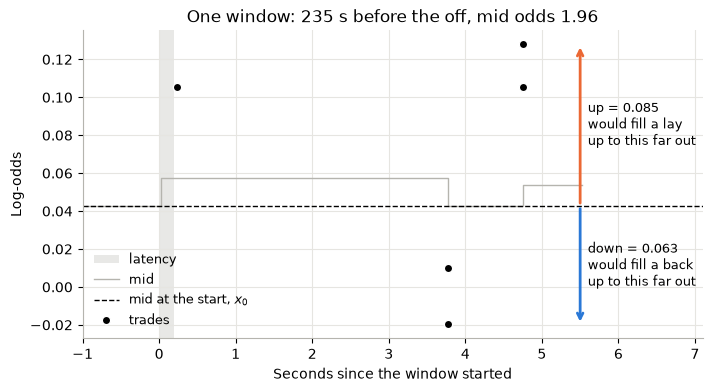

In [4]:
race = FILES[0]
in_race = windows[windows["race"] == race.stem]
favourite = in_race.loc[in_race["t"] == in_race["t"].max()].sort_values("odds")["selection_id"].iloc[0]  # shortest odds
w = in_race[(in_race["selection_id"] == favourite) & (in_race["down"] > 0) & (in_race["up"] > 0)].iloc[0]

book = load_book(race)
book = book[book["selection_id"] == favourite]
trades = trade_list(book)
since_start = w["t"] - book["ttj"]                     # seconds since the window started
trade_secs = w["t"] - trades["ttj"]
live = (trade_secs > LATENCY) & (trade_secs <= LATENCY + WINDOW)

fig, ax = plt.subplots()
ax.axvspan(0, LATENCY, color=GREY, alpha=0.3, lw=0, label="latency")
shown = since_start.between(-1, LATENCY + WINDOW + 0.5)
ax.step(since_start[shown], book["x"][shown], where="post", color=GREY, lw=1, label="mid")
ax.axhline(w["x0"], color="black", lw=1, ls="--", label="mid at the start, $x_0$")
ax.plot(trade_secs[live], trades["x"][live], "o", color="black", ms=6, mec="white", label="trades")

# Arrows from the starting mid to the lowest and highest trades
end = LATENCY + WINDOW + 0.3
for side, sign in [("back", -1), ("lay", 1)]:
    distance = w[SIDES[side]]
    ax.annotate("", xy=(end, w["x0"] + sign * distance), xytext=(end, w["x0"]),
                arrowprops=dict(arrowstyle="->", color=COLOURS[side], lw=2))
    ax.text(end + 0.1, w["x0"] + sign * distance / 2,
            f"{SIDES[side]} = {distance:.3f}\nwould fill a {side}\nup to this far out", va="center", fontsize=9)
ax.set(xlim=(-1, end + 1.6), xlabel="Seconds since the window started", ylabel="Log-odds",
       title=f"One window: {w['t']} s before the off, mid odds {w['odds']:.2f}")
ax.legend(frameon=False, loc="lower left", fontsize=9)
plt.show()

## Step 2: Fill probability and fill rate

Each window goes in the time bin of its **start**. Bins are written as (lower, upper], e.g. (30, 45], and named by their upper edge, exactly as in the σ² notebook. That's how `asmodel.py` looks up its tables (`seconds_to_off <= edge`), and it gives the window starting at 350 s a bin. The guide writes the bins as [lower, upper). The only difference is which bin a window starting exactly on an edge (45, 60, 90, …) belongs to.

In one bin and on one side, say there are $n$ windows and a quote at distance δ would have been filled in $h(\delta)$ of them. The **fill probability** is

$$P(\delta) = \frac{h(\delta)}{n}$$

the chance that a quote at δ is filled within 5 seconds.

A–S needs a **rate** (fills per second), not a probability. It assumes fills arrive at random at a steady rate λ (a Poisson process), so the chance of at least one fill in 5 seconds is $P = 1 - e^{-5\lambda}$. Solving for λ:

$$\lambda(\delta) = -\frac{\ln\big(1-P(\delta)\big)}{5}$$

For small $P$ this is about $P/5$: P = 0.05 gives λ = 0.0103 per second. For larger P it's bigger than P/5, because a window only tells us whether there was *at least one* fill, and could hide several: P = 0.6 gives λ = 0.18, not 0.12.

**Totals by race.** As with σ², everything we need can be built from totals per race. For each race and bin we count the windows, and, for each δ, how many of them would have filled a back (and a lay). Every estimate is then a **weighted sum over races**:

- the **pooled** estimate gives every race a weight of 1;
- a **bootstrap** sample weights each race by how many times it was drawn;
- a **daily** estimate gives that day's races a weight of 1 and the rest 0.

In [5]:
windows["bin"] = pd.cut(windows["t"], BIN_EDGES, labels=BINS).astype(int)   # (30, 45] -> 45, ..., (300, 350] -> 350
LABELS = {hi: f"({lo}, {hi}]" for lo, hi in zip(BIN_EDGES[:-1], BIN_EDGES[1:])}
RACES = windows["race"].unique()


def race_totals(values):
    # Add up `values` (one row per window) within each race and bin -> array indexed [race, bin, column]
    totals = values.groupby([windows["race"], windows["bin"]]).sum()
    every_cell = pd.MultiIndex.from_product([RACES, BINS])     # include bins where a race has no windows
    return totals.reindex(every_cell, fill_value=0).to_numpy().reshape(len(RACES), len(BINS), -1)


# window_counts[race, bin] = number of windows
window_counts = race_totals(pd.DataFrame({"windows": 1}, index=windows.index))[:, :, 0]

# fill_counts[side][race, bin, j] = windows in which that side's quote at distance DELTAS[j] would have been filled.
# A window with no trades has down = up = NaN, and NaN >= δ is False, so it counts as no fill.
fill_counts = {side: race_totals(pd.DataFrame({d: windows[column] >= d for d in DELTAS}))
               for side, column in SIDES.items()}


def totals(weights, side):
    # Weighted sum over races: windows per bin, and fills per bin and distance
    return weights @ window_counts, np.tensordot(weights, fill_counts[side], axes=1)


EVERY_RACE = np.ones(len(RACES))     # weights for the pooled estimate
pd.Series(window_counts.sum(axis=0), index=[LABELS[b] for b in BINS], name="windows").rename_axis("seconds before off")

seconds before off
(30, 45]       25996
(45, 60]       26019
(60, 90]       52084
(90, 120]      52059
(120, 180]    104127
(180, 240]    102299
(240, 300]     99077
(300, 350]     79984
Name: windows, dtype: int64

Here is the fill probability against distance for four of the bins. Close to the off, a quote near the mid is far more likely to be filled: over half the windows in the last 45 seconds at δ = 0.01, against about 5% at 300–350 s. But that chance falls away much faster with distance, and by δ ≈ 0.08 the four bins are about level. A steeper fall is exactly what a larger $k$ means.

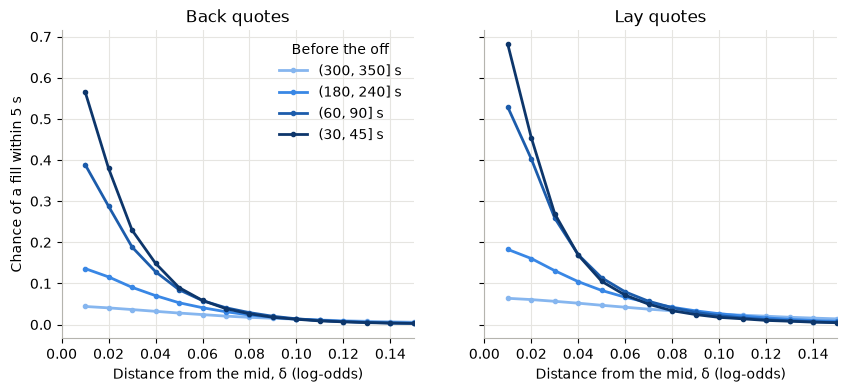

In [6]:
SHOWN = [350, 240, 90, 45]                              # far from the off ... close to it
RAMP = ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]     # light = far from the off, dark = close to it

fig, axes = plt.subplots(1, 2, sharey=True, figsize=(10, 4))
for ax, side in zip(axes, SIDES):
    n_tot, h_tot = totals(EVERY_RACE, side)
    for b, colour in zip(SHOWN, RAMP):
        i = BINS.index(b)
        ax.plot(DELTAS, h_tot[i] / n_tot[i], "-o", color=colour, lw=2, ms=3, label=f"{LABELS[b]} s")
    ax.set(title=f"{side.title()} quotes", xlabel="Distance from the mid, δ (log-odds)", xlim=(0, 0.15))
axes[0].set(ylabel="Chance of a fill within 5 s")
axes[0].legend(title="Before the off", frameon=False)
plt.show()

## Step 3: Fit a straight line to find k

Taking logs of $\lambda(\delta) = A\,e^{-k\delta}$ gives a straight line:

$$\ln\lambda(\delta) = \ln A - k\,\delta$$

So in each bin we plot ln λ against δ, fit a line by ordinary least squares, and read off $k = -\text{slope}$.

We only use the distances where $0.02 < P(\delta) < 0.98$:

- Below 2%, the probability rests on very few fills, so its log is noisy (and with no fills at all, it's $-\infty$).
- Above 98%, $-\ln(1-P)$ blows up, so tiny changes in P make huge changes in λ.

A bin needs at least 3 usable distances, otherwise it can't be fitted. In practice P never gets near 98%, so the 2% floor decides how far out we fit.

In [7]:
def fill_rates(n, h, p_range=P_RANGE):
    # Fill probability and fill rate at each distance, and which distances the fit may use
    P = h / n if n > 0 else np.zeros(len(DELTAS))
    rate = -np.log(1 - P) / WINDOW
    usable = (P > p_range[0]) & (P < p_range[1])
    return P, rate, usable


def fit_k(n, h, p_range=P_RANGE):
    # k for one bin, from n windows and h[j] = windows filled at distance DELTAS[j] (NaN if it can't be fitted)
    P, rate, usable = fill_rates(n, h, p_range)
    if usable.sum() < 3:
        return np.nan
    slope, intercept = np.polyfit(DELTAS[usable], np.log(rate[usable]), 1)
    return -slope


def k_by_group(weights, side, groups, p_range=P_RANGE):
    # k for each group of bins (a group is a list of bin positions), from a weighted sum of race totals
    n_tot, h_tot = totals(weights, side)
    return np.array([fit_k(n_tot[g].sum(), h_tot[g].sum(axis=0), p_range) for g in groups])


ONE_BIN_EACH = [[i] for i in range(len(BINS))]
k_per_bin = {side: k_by_group(EVERY_RACE, side, ONE_BIN_EACH) for side in SIDES}
pd.DataFrame(k_per_bin, index=[LABELS[b] for b in BINS]).rename_axis("seconds before off").round(1)

,back,lay
seconds before off,,
"(30, 45]",49.4,47.5
"(45, 60]",39.9,43.7
"(60, 90]",40.2,39.6
"(90, 120]",37.5,37.8
"(120, 180]",33.6,31.0
"(180, 240]",26.6,23.1
"(240, 300]",19.0,16.5
"(300, 350]",13.0,11.0


Each panel below is one bin. Filled dots are the distances used in the fit, and hollow dots are the distances left out because fewer than 2% of windows reached them. **A straight line through the filled dots means A–S's exponential assumption holds.**

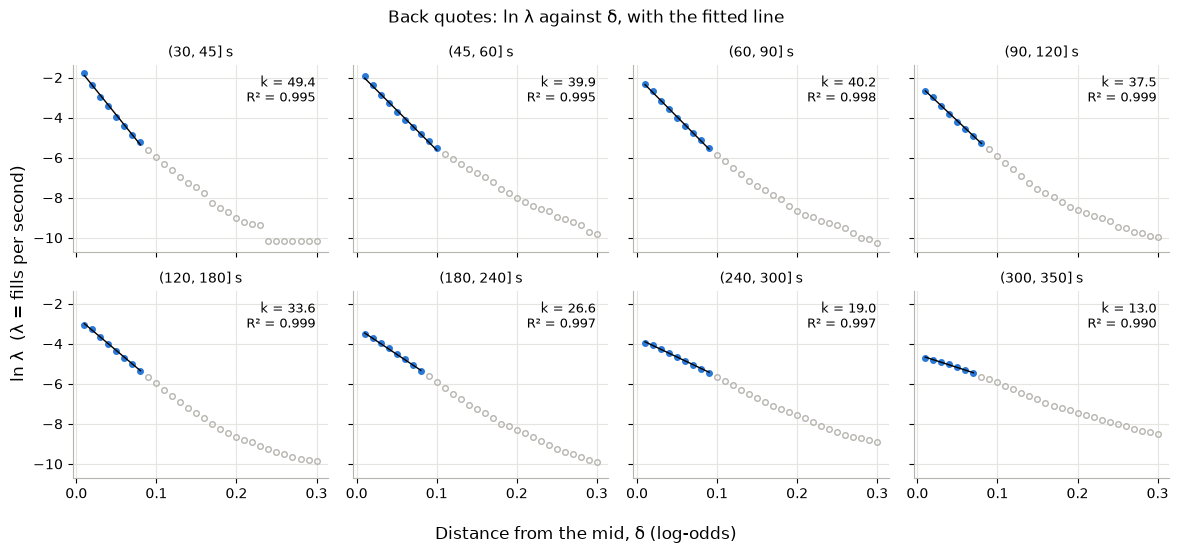

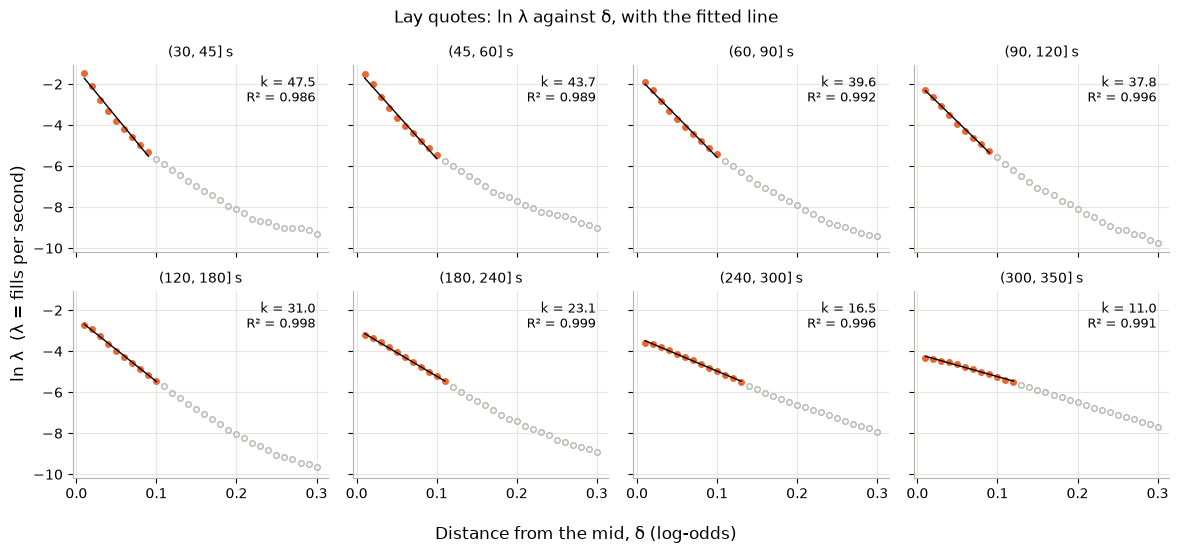

In [8]:
for side in SIDES:
    n_tot, h_tot = totals(EVERY_RACE, side)
    fig, axes = plt.subplots(2, 4, figsize=(12, 5.5), sharex=True, sharey=True)
    for i, ax in enumerate(axes.flat):
        P, rate, usable = fill_rates(n_tot[i], h_tot[i])
        left_out = ~usable & (P > 0)                    # P = 0 can't be drawn: ln(0) = -inf
        ax.plot(DELTAS[left_out], np.log(rate[left_out]), "o", mfc="none", mec=GREY, ms=4)
        ax.plot(DELTAS[usable], np.log(rate[usable]), "o", color=COLOURS[side], ms=4)
        if usable.sum() >= 3:
            slope, intercept = np.polyfit(DELTAS[usable], np.log(rate[usable]), 1)
            r2 = np.corrcoef(DELTAS[usable], np.log(rate[usable]))[0, 1] ** 2
            ax.plot(DELTAS[usable], intercept + slope * DELTAS[usable], color="black", lw=1)
            ax.text(0.95, 0.95, f"k = {-slope:.1f}\nR² = {r2:.3f}", transform=ax.transAxes,
                    ha="right", va="top", fontsize=9)
        ax.set_title(f"{LABELS[BINS[i]]} s", fontsize=10)
    fig.supxlabel("Distance from the mid, δ (log-odds)")
    fig.supylabel("ln λ  (λ = fills per second)")
    fig.suptitle(f"{side.title()} quotes: ln λ against δ, with the fitted line")
    fig.tight_layout()
    plt.show()

The filled dots sit on a straight line in every bin, with R² of at least 0.98, so the exponential model fits the distances we use well. The hollow dots past the cut-off bend away from the line: very distant fills (a big price jump within 5 seconds) are more common than the exponential predicts. Those distances hold under 2% of windows and are well beyond where the strategy quotes, so leaving them out is what we want.

## Step 4: Problem bins

The guide's rule: if a bin gives $k$ below 2, or can't be fitted, merge it with a neighbouring bin and fit again, so that no number is ever typed in by hand. We merge it with whichever neighbour has fewer windows (the end bins have only one neighbour) and repeat until every bin passes. Each side is checked separately.

In [9]:
def merge_problem_bins(side):
    # Start with every bin on its own. While some group has k below MIN_K or can't be fitted, merge it with
    # its neighbouring group that has fewer windows, then refit. Returns the groups as lists of bin positions.
    groups = [[i] for i in range(len(BINS))]
    while len(groups) > 1:
        ks = k_by_group(EVERY_RACE, side, groups)
        problems = [i for i, k in enumerate(ks) if not k >= MIN_K]     # `not k >= 2` is also True for NaN
        if not problems:
            break
        i = problems[0]
        neighbours = [j for j in (i - 1, i + 1) if 0 <= j < len(groups)]
        j = min(neighbours, key=lambda j: window_counts[:, groups[j]].sum())
        lo, hi = sorted((i, j))
        groups[lo:hi + 1] = [groups[lo] + groups[hi]]
    return groups


def group_label(group):
    # e.g. [0] -> "(30, 45]", and [0, 1] -> "(30, 60]" if two bins were merged
    return f"({BIN_EDGES[group[0]]}, {BIN_EDGES[group[-1] + 1]}]"


groups = {side: merge_problem_bins(side) for side in SIDES}
for side in SIDES:
    merged = [group_label(g) for g in groups[side] if len(g) > 1]
    print(f"{side}: " + (f"merged into {', '.join(merged)}" if merged else f"no problem bins, all {len(BINS)} kept"))

back: no problem bins, all 8 kept
lay: no problem bins, all 8 kept


## Step 5: 95% confidence intervals (bootstrap by race)

As for σ², we resample **whole races**, not single windows. Runners in the same race are linked (when one shortens, others must drift), and a burst of news or a big punter hits the whole race at once. Treating every window as independent would make the intervals too narrow.

1. Draw $R$ races at random with replacement, where $R$ is the number of races.
2. Recompute $k$ from the drawn races, counting a race twice if it was drawn twice.
3. Repeat 1,000 times, sort the results, and take the 25th and 975th smallest values.

With the race totals from Step 2, a bootstrap sample is just a set of weights: how many times each race was drawn. `rng.multinomial` draws all 1,000 sets of weights at once. It's the same as picking $R$ races with replacement and counting how often each came up.

In [10]:
R = len(RACES)
draws = rng.multinomial(R, np.full(R, 1 / R), size=N_BOOT)   # draws[b, r] = times race r was picked in repeat b

boot = {side: np.array([k_by_group(weights, side, groups[side]) for weights in draws])   # repeats x bins
        for side in SIDES}
for side in SIDES:
    assert not np.isnan(boot[side]).any(), f"some {side} bootstrap samples couldn't be fitted"
ci = {side: np.sort(boot[side], axis=0)[[24, 974]] for side in SIDES}    # 25th and 975th smallest of 1,000

## Step 6: Is it stable from day to day?

We repeat the estimate using one day's races at a time. If $k$ jumped around a lot between days, a single month's average wouldn't be a reliable number to trade on. For each bin we record the median, minimum and maximum across the 31 days, and the **coefficient of variation** (CV = standard deviation ÷ mean). A CV of 0.2 means a typical day is about 20% away from the average.

Problem bins are only merged for the pooled estimate. A single day's bin has far fewer windows, so if it can't be fitted we leave it out of that day's numbers rather than merge.

In [11]:
race_day = windows.groupby("race")["day"].first().loc[RACES].to_numpy()    # the day of each race, in RACES order
DAYS = np.unique(race_day)
daily = {side: np.array([k_by_group((race_day == day).astype(float), side, groups[side]) for day in DAYS])
         for side in SIDES}                                                  # days x bins
for side in SIDES:
    print(f"{side}: {np.isnan(daily[side]).sum()} of {daily[side].size} day-and-bin estimates couldn't be fitted")

back: 0 of 248 day-and-bin estimates couldn't be fitted
lay: 0 of 248 day-and-bin estimates couldn't be fitted


## Spread check

The guide asks for one more check that the method makes sense: how wide is the market itself? For every book update in the window (350 s to 30 s, market open, mid odds 1.2–6.0) we measure the gap between the best back odds $B$ and the best lay odds $L$:

- in **ticks** on the price ladder;
- as a **half-spread** in log-odds, $\tfrac12\left[\ln(L-1) - \ln(B-1)\right]$, which is about how far each side of the book sits from the mid.

We report the median of each per bin. To keep memory low, each race reports how many updates showed each $(B, L)$ pair, and the medians are taken over those counts.

We compare the half-spread with $1/k$. A–S's half-spread is a volatility term plus a fill term, $\frac1\gamma\ln\left(1+\frac\gamma k\right)$. The fill term is never more than $1/k$, and is close to it when $\gamma$ is small next to $k$. So $1/k$ is a rough guide to how far from the mid A–S would quote, before the volatility and inventory terms are added.

In [12]:
def spreads_in_race(path):
    # How many book updates in the window showed each (best back, best lay) pair, per time bin
    book = load_book(path)
    counted = (book["status"] == "OPEN") & book["ttj"].between(30, 350) & book["odds"].between(MIN_ODDS, MAX_ODDS)
    book = book[counted]
    time_bin = pd.cut(book["ttj"], BIN_EDGES, labels=BINS).rename("bin")
    return book.groupby([time_bin, "back_price_1", "lay_price_1"], observed=True).size()


spreads = pd.concat([spreads_in_race(f) for f in FILES])              # takes about a minute
spreads = spreads.groupby(level=[0, 1, 2]).sum().rename("updates").reset_index()
B, L = spreads["back_price_1"], spreads["lay_price_1"]


def ladder_position(price):
    # Where each price sits on the ladder (1.01 is 0, 1.02 is 1, ...), so a difference counts ticks
    return np.searchsorted(LADDER, price - 1e-9)


spreads["ticks"] = ladder_position(L) - ladder_position(B)
spreads["half_spread"] = 0.5 * (np.log(L - 1) - np.log(B - 1))


def weighted_median(values, weights):
    # The value with half of the total weight at or below it
    order = np.argsort(values)
    cumulative = np.cumsum(weights[order])
    return values[order][np.searchsorted(cumulative, cumulative[-1] / 2)]


by_bin = spreads.groupby("bin", observed=True)
spread_check = pd.DataFrame({
    "book updates": by_bin["updates"].sum(),
    "median spread (ticks)": by_bin.apply(lambda g: weighted_median(g["ticks"].to_numpy(), g["updates"].to_numpy())),
    "median half-spread": by_bin.apply(lambda g: weighted_median(g["half_spread"].to_numpy(), g["updates"].to_numpy())),
    "1/k back": 1 / k_per_bin["back"],
    "1/k lay": 1 / k_per_bin["lay"],
})
spread_check.index = [LABELS[b] for b in spread_check.index]
spread_check.index.name = "seconds before off"
spread_check.round(3)

,book updates,median spread (ticks),median half-spread,1/k back,1/k lay
seconds before off,,,,,
"(30, 45]",1136956,2,0.017,0.020,0.021
"(45, 60]",1167534,2,0.020,0.025,0.023
"(60, 90]",2131424,2,0.023,0.025,0.025
"(90, 120]",1996432,3,0.026,0.027,0.026
"(120, 180]",3797994,3,0.033,0.030,0.032
"(180, 240]",3747678,5,0.053,0.038,0.043
"(240, 300]",3652555,9,0.088,0.053,0.061
"(300, 350]",1516586,13,0.124,0.077,0.091


**What the spread check tells us.**

- **The distances we fit are the ones that matter.** The fit uses δ from 0.01 out to about 0.07–0.13 (where P drops below 2%). Near the off, the median half-spread is about 0.02, so that range runs from the best prices out to several ticks behind them. Far from the off the book is much wider (13 ticks across, a half-spread of about 0.12), so the fitted distances are mostly *inside* the spread, where our quote would be the new best price. The "furthest trade" rule from Step 1 handles that case correctly.
- **The k values give sensible quotes.** $1/k$ is close to the market's own half-spread in the last two minutes. Further from the off it's well inside it, so A–S would quote inside a wide, thin book, ahead of everyone else. Both follow the same pattern: wide early and tight near the off.

## Robustness checks

Each check recomputes the pooled $k$ a different way. If the numbers barely move, the main estimate doesn't depend on that choice.

1. **Runners near the 1.2 and 6.0 edges.** (a) Only use runners whose mid odds stayed between 1.2 and 6.0 at every window start from 350 s to 35 s, so runners that cross an edge are out completely. (b) Only use windows that start comfortably inside the range, at odds 1.3–5.0.
2. **Which distances go into the fit.** Use a looser cut (1% < P < 99%) and a stricter one (5% < P < 95%) instead of 2%–98%.
3. **Does k depend on the odds?** Fit favourites and shorter-priced runners (odds 1.2–3.0) separately from longer-priced ones (3.0–6.0).

For one-off checks like these, it's simpler to count fills straight from a table of windows than to build race totals, so we do that (and first confirm it matches the main estimate).

In [13]:
def k_from_windows(subset, side, p_range=P_RANGE):
    # Pooled k for each group of bins, counted straight from a table of windows
    ks = []
    for g in groups[side]:
        distance = subset.loc[subset["bin"].isin([BINS[i] for i in g]), SIDES[side]]
        ks.append(fit_k(len(distance), np.array([(distance >= d).sum() for d in DELTAS]), p_range))
    return np.array(ks)


for side in SIDES:     # the shortcut gives the same answer as the race totals
    assert np.allclose(k_from_windows(windows, side), k_by_group(EVERY_RACE, side, groups[side]))

# Runners whose mid odds stayed in range at every window start where the market was open
odds_seen = all_windows[all_windows["open"]].groupby(["race", "selection_id"])["odds"].agg(["min", "max"])
steady = odds_seen[(odds_seen["min"] >= MIN_ODDS) & (odds_seen["max"] <= MAX_ODDS)].index
is_steady = pd.MultiIndex.from_frame(windows[["race", "selection_id"]]).isin(steady)
print(f"{is_steady.mean():.0%} of windows come from runners that never left 1.2-6.0")

CHECKS = {
    "main estimate": (windows, P_RANGE),
    "1a: always in range": (windows[is_steady], P_RANGE),
    "1b: odds 1.3-5.0": (windows[windows["odds"].between(1.3, 5.0)], P_RANGE),
    "2: fit 1%-99%": (windows, (0.01, 0.99)),
    "2: fit 5%-95%": (windows, (0.05, 0.95)),
    "3: odds 1.2-3.0": (windows[windows["odds"] <= 3.0], P_RANGE),
    "3: odds 3.0-6.0": (windows[windows["odds"] > 3.0], P_RANGE),
}
robustness = pd.concat({
    side: pd.DataFrame({name: k_from_windows(subset, side, p_range) for name, (subset, p_range) in CHECKS.items()},
                       index=[group_label(g) for g in groups[side]])
    for side in SIDES
}, names=["side", "seconds before off"])
robustness.round(1)

85% of windows come from runners that never left 1.2-6.0


main estimate  1a: always in range  1b: odds 1.3-5.0  \
side seconds before off                                                         
back (30, 45]                     49.4                 50.4              49.8   
     (45, 60]                     39.9                 42.2              41.5   
     (60, 90]                     40.2                 41.9              40.6   
     (90, 120]                    37.5                 38.4              37.9   
     (120, 180]                   33.6                 34.2              33.6   
     (180, 240]                   26.6                 27.4              27.2   
     (240, 300]                   19.0                 19.8              19.5   
     (300, 350]                   13.0                 12.8              13.5   
lay  (30, 45]                     47.5                 48.0              47.8   
     (45, 60]                     43.7                 44.1              44.1   
     (60, 90]                     39.6                 39.8              40.0   
     (90, 120]                    37.8                 38.0              38.1   
     (120, 180]                   31.0                 30.9              31.0   
     (180, 240]                   23.1                 23.1              23.4   
     (240, 300]                   16.5                 16.7              17.0   
     (300, 350]                   11.0                 11.0              11.6   

                         2: fit 1%-99%  2: fit 5%-95%  3: odds 1.2-3.0  \
side seconds before off                                                  
back (30, 45]                     46.4           52.8             50.4   
     (45, 60]                     38.0           43.4             42.5   
     (60, 90]                     39.0           42.8             42.4   
     (90, 120]                    36.5           38.2             39.6   
     (120, 180]                   33.2           33.2             36.0   
     (180, 240]                   27.3           25.0             29.2   
     (240, 300]                   19.5           16.2             22.0   
     (300, 350]                   14.3            NaN             16.3   
lay  (30, 45]                     41.9           55.1             48.6   
     (45, 60]                     40.8           48.8             43.8   
     (60, 90]                     37.5           43.7             41.0   
     (90, 120]                    35.7           41.0             39.5   
     (120, 180]                   30.5           32.0             31.7   
     (180, 240]                   23.4           22.4             24.3   
     (240, 300]                   16.8           14.7             19.5   
     (300, 350]                   11.7            7.1             14.3   

                         3: odds 3.0-6.0  
side seconds before off                   
back (30, 45]                       49.0  
     (45, 60]                       39.1  
     (60, 90]                       39.1  
     (90, 120]                      36.3  
     (120, 180]                     32.1  
     (180, 240]                     25.1  
     (240, 300]                     16.8  
     (300, 350]                      9.7  
lay  (30, 45]                       47.1  
     (45, 60]                       43.7  
     (60, 90]                       38.9  
     (90, 120]                      36.9  
     (120, 180]                     30.6  
     (180, 240]                     22.3  
     (240, 300]                     14.5  
     (300, 350]                      8.5

- **Edges (1a, 1b).** Dropping runners that ever cross 1.2 or 6.0, or windows that start near the edges, changes $k$ by less than about 6%. Runners hovering around the edges don't drive the estimate, so filtering at the start of the window is safe.
- **Fit range (2).** This is the most sensitive choice. In most bins a looser or stricter cut moves $k$ by up to about 15%. The curve isn't a perfect straight line over every distance, so $k$ depends a little on which distances it's fitted to, and the guide's 2%–98% sits between the two. The earliest bin is the exception. Fewer than 5% of its windows fill a back even at δ = 0.01, so with the 5% cut the back has no usable distances at all, and the lay fit rests on just four points.
- **Odds (3).** Far from the off, $k$ is larger for shorter-priced runners: at 300–350 s it's about 1.7 times the value for runners priced 3.0–6.0. The gap shrinks towards the off, and in the last two minutes the two groups are within about 10% of each other. So our single $k$ per bin is an average over runners. It's accurate close to the off, where most of the trading happens, and a compromise earlier on.

## Results

All $k$ values are in log-odds units (per unit of log-odds distance).

In [14]:
def summary(side):
    gs = groups[side]
    d = daily[side]
    return pd.DataFrame({
        "windows": [window_counts[:, g].sum() for g in gs],
        "k": k_by_group(EVERY_RACE, side, gs),
        "95% CI low": ci[side][0],
        "95% CI high": ci[side][1],
        "daily median": np.nanmedian(d, axis=0),
        "daily min": np.nanmin(d, axis=0),
        "daily max": np.nanmax(d, axis=0),
        "daily CV": np.nanstd(d, axis=0, ddof=1) / np.nanmean(d, axis=0),
    }, index=[group_label(g) for g in gs])


results = pd.concat({side: summary(side) for side in SIDES}, names=["side", "seconds before off"])
results.round(2)

windows      k  95% CI low  95% CI high  \
side seconds before off                                            
back (30, 45]              25996  49.45       48.40        50.62   
     (45, 60]              26019  39.86       38.85        41.81   
     (60, 90]              52084  40.22       39.35        41.75   
     (90, 120]             52059  37.48       36.39        38.44   
     (120, 180]           104127  33.55       32.84        34.23   
     (180, 240]           102299  26.58       25.81        27.32   
     (240, 300]            99077  19.03       18.37        19.69   
     (300, 350]            79984  13.00       11.95        13.84   
lay  (30, 45]              25996  47.53       46.44        48.56   
     (45, 60]              26019  43.69       42.72        46.22   
     (60, 90]              52084  39.61       38.80        40.37   
     (90, 120]             52059  37.81       36.24        38.64   
     (120, 180]           104127  31.01       30.38        31.68   
     (180, 240]           102299  23.09       22.48        23.60   
     (240, 300]            99077  16.46       15.94        16.79   
     (300, 350]            79984  11.02       10.49        11.44   

                         daily median  daily min  daily max  daily CV  
side seconds before off                                                
back (30, 45]                   48.62      35.62      59.27      0.12  
     (45, 60]                   40.18      33.30      51.30      0.10  
     (60, 90]                   40.18      35.62      50.30      0.09  
     (90, 120]                  37.52      31.45      49.31      0.11  
     (120, 180]                 33.46      27.38      38.79      0.08  
     (180, 240]                 26.15      20.59      32.95      0.11  
     (240, 300]                 18.88      14.16      26.36      0.14  
     (300, 350]                 12.05       3.59      20.79      0.30  
lay  (30, 45]                   48.31      30.92      60.46      0.13  
     (45, 60]                   44.25      33.48      52.32      0.11  
     (60, 90]                   40.26      33.00      54.92      0.13  
     (90, 120]                  37.88      27.82      45.03      0.11  
     (120, 180]                 31.79      24.43      37.98      0.11  
     (180, 240]                 23.77      16.44      28.95      0.12  
     (240, 300]                 16.60      11.37      20.41      0.15  
     (300, 350]                 11.03       7.01      17.90      0.19

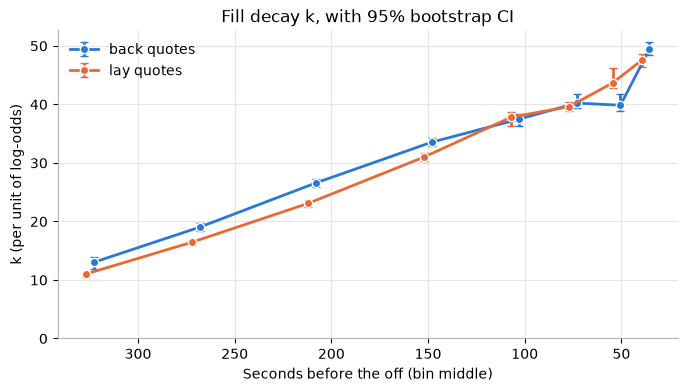

In [15]:
def middles(side):
    # Middle of each group of bins, in seconds before the off (for plotting)
    return np.array([(BIN_EDGES[g[0]] + BIN_EDGES[g[-1] + 1]) / 2 for g in groups[side]])


fig, ax = plt.subplots()
for side, nudge in [("back", -2), ("lay", 2)]:      # nudge the two sides apart so their error bars don't overlap
    k = results.loc[side, "k"].to_numpy()
    ax.errorbar(middles(side) + nudge, k, yerr=[k - ci[side][0], ci[side][1] - k],
                fmt="-o", color=COLOURS[side], lw=2, ms=6, mec="white", capsize=3, label=f"{side} quotes")
ax.invert_xaxis()   # time runs left to right, towards the off
ax.set(xlabel="Seconds before the off (bin middle)", ylabel="k (per unit of log-odds)",
       title="Fill decay k, with 95% bootstrap CI", ylim=(0, None))
ax.legend(frameon=False)
plt.show()

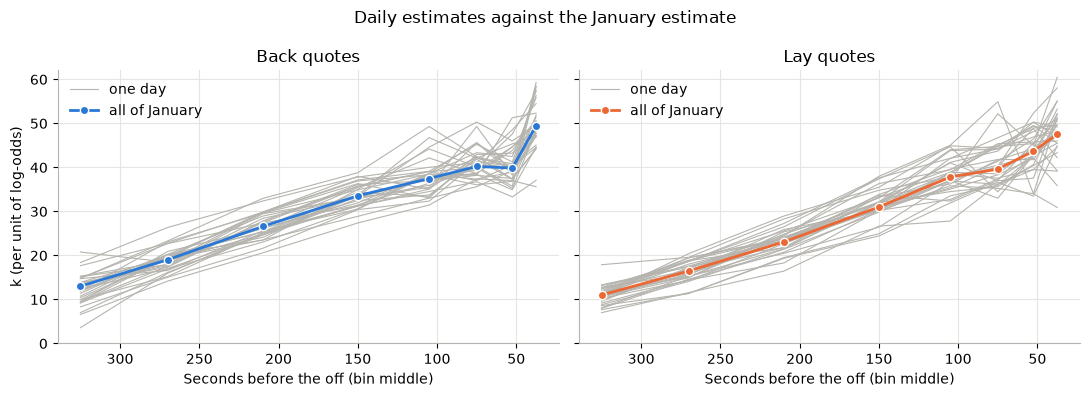

In [16]:
fig, axes = plt.subplots(1, 2, sharey=True, figsize=(11, 4))
for ax, side in zip(axes, SIDES):
    day_lines = ax.plot(middles(side), daily[side].T, color=GREY, lw=0.8)    # one grey line per day
    day_lines[0].set_label("one day")
    ax.plot(middles(side), results.loc[side, "k"], "-o", color=COLOURS[side], lw=2, ms=6, mec="white",
            label="all of January")
    ax.invert_xaxis()
    ax.set(title=f"{side.title()} quotes", xlabel="Seconds before the off (bin middle)", ylim=(0, None))
    ax.legend(frameon=False)
axes[0].set(ylabel="k (per unit of log-odds)")
fig.suptitle("Daily estimates against the January estimate")
fig.tight_layout()
plt.show()

## Table for the strategy

`asmodel.py` reads each $k$ table as a list of `(upper edge in seconds, value)`. The last edge becomes `INF`, so the final value also covers anything further from the off. If any bins were merged in Step 4, the merged bin appears once, under its upper edge.

In [17]:
for side in SIDES:
    edges = [str(BIN_EDGES[g[-1] + 1]) for g in groups[side][:-1]] + ["INF"]
    values = results.loc[side, "k"]
    print(f"K_{side.upper()}_X = [" + ", ".join(f"({e}, {v:.1f})" for e, v in zip(edges, values)) + "]")

K_BACK_X = [(45, 49.4), (60, 39.9), (90, 40.2), (120, 37.5), (180, 33.6), (240, 26.6), (300, 19.0), (INF, 13.0)]
K_LAY_X = [(45, 47.5), (60, 43.7), (90, 39.6), (120, 37.8), (180, 31.0), (240, 23.1), (300, 16.5), (INF, 11.0)]


## Reading the results

- **Shape.** $k$ rises steadily towards the off, from about 11–13 at 300–350 s to about 48 at 30–45 s, roughly four times larger. Close to the off, fills fall away with distance much faster.
- **In plain terms.** One tick is about 0.02 in log-odds. Moving a quote one tick further from the mid multiplies its fill rate by $e^{-0.02k}$. At $k = 13$ the quote keeps 77% of its fills, but at $k = 48$ it keeps only 38%. Early on, stepping back costs little. In the last minute, every tick costs more than half the fills.
- **Back vs lay.** The two sides are close, but not the same. More than 120 s before the off, the lay's $k$ is a little smaller than the back's, and their confidence intervals don't overlap. In the last two minutes they're closer and swap order. Near the mid, lays are also filled more often than backs (28% of windows against 21% at δ = 0.01). So keeping the sides separate, as the guide asks, is worth it.
- **Precision.** With almost 4,000 races, every 95% interval is within about 8% of its estimate.
- **Day to day.** In most bins a typical day is within 8–15% of the January value (daily CV 0.08–0.15), so $k$ is steadier than σ² (CV 0.20–0.35). The exception is the earliest bin, 300–350 s (CV 0.30 for backs, 0.19 for lays), where trading is thinnest. Every day shows the same rising shape.
- **Robustness.** The exponential shape fits well (R² of at least 0.986), and runners near the 1.2 and 6.0 edges don't move the estimate. The biggest sensitivities are which distances go into the fit (up to about 15%) and, far from the off, the runner's odds.
- **Compared with the placeholders in `asmodel.py`.** The values currently in the file (`K_BACK_X = [(60, 40.0), (120, 29.0), (300, 18.0), (INF, 6.0)]`, and slightly lower for lays) are about equal to or below our estimates in every bin, often by a third or more. A larger $k$ means a smaller fill term in the spread, so switching to these tables will tighten the strategy's quotes.
- **One limitation: queue position.** The "furthest trade" rule assumes our quote is first in line at its price. If others were already waiting at the same price, a trade there might have filled them and not us. Far from the off this hardly matters, because A–S would quote inside a wide book and be first in line anyway. Near the off the book is about 2 ticks wide, and our quote would often join a price where others are already waiting. There we overstate fills at the smallest distances, so the true $k$ is probably a little lower than our estimate. The backtest engine models the queue, so the backtest's own fills are the real test.